In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

RANDOM_STATE = 42


In [ ]:
wine = load_wine(as_frame=True)
X = wine.data.copy()
y = wine.target.copy()

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
cultivar_names = {i: name for i, name in enumerate(wine.target_names)}

print(f"Observations: {X.shape[0]}")
print(f"Predictor features: {X.shape[1]}")
print("Cultivars (not used to fit clusters):", cultivar_names)
X.head()


Observations: 178
Predictor features: 13
Cultivars (not used to fit clusters): {0: np.str_('class_0'), 1: np.str_('class_1'), 2: np.str_('class_2')}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:
k_values = range(2, 11)
results = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_scaled)
    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
    })

results_df = pd.DataFrame(results)
best_k = int(results_df.loc[results_df["silhouette"].idxmax(), "k"])
print(f"Selected k={best_k}: highest mean silhouette score in the tested range.")
results_df


Selected k=3: highest mean silhouette score in the tested range.


,k,inertia,silhouette
0,2,1658.758852,0.259317
1,3,1277.928489,0.284859
2,4,1175.351881,0.258608
3,5,1107.007343,0.231528
4,6,1046.002333,0.237167
5,7,981.595233,0.203628
6,8,935.201211,0.157014
7,9,889.892911,0.149882
8,10,845.895237,0.143638


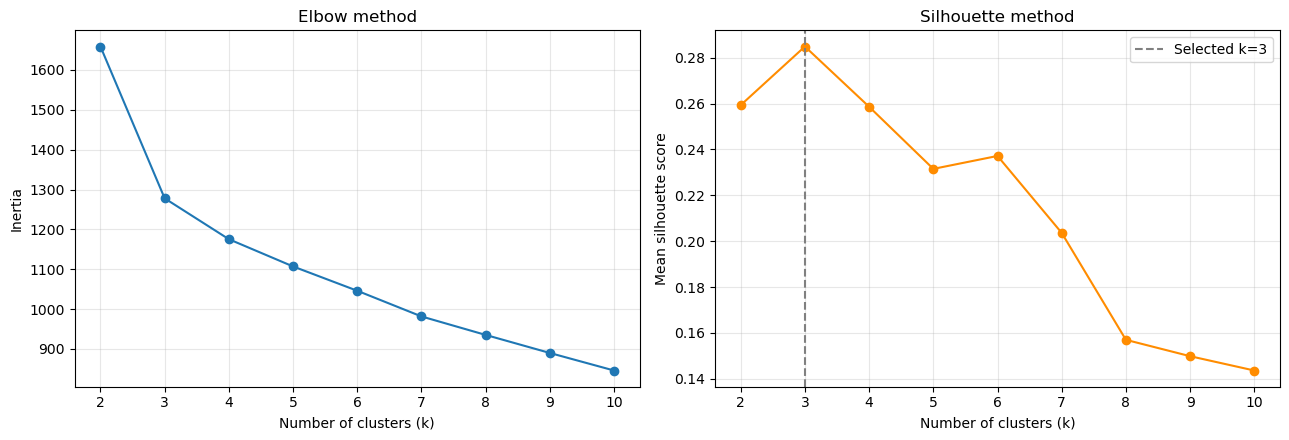

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(results_df["k"], results_df["inertia"], marker="o")
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(alpha=0.3)

axes[1].plot(results_df["k"], results_df["silhouette"], marker="o", color="darkorange")
axes[1].axvline(best_k, color="gray", linestyle="--", label=f"Selected k={best_k}")
axes[1].set(title="Silhouette method", xlabel="Number of clusters (k)", ylabel="Mean silhouette score")
axes[1].set_xticks(list(k_values))
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()


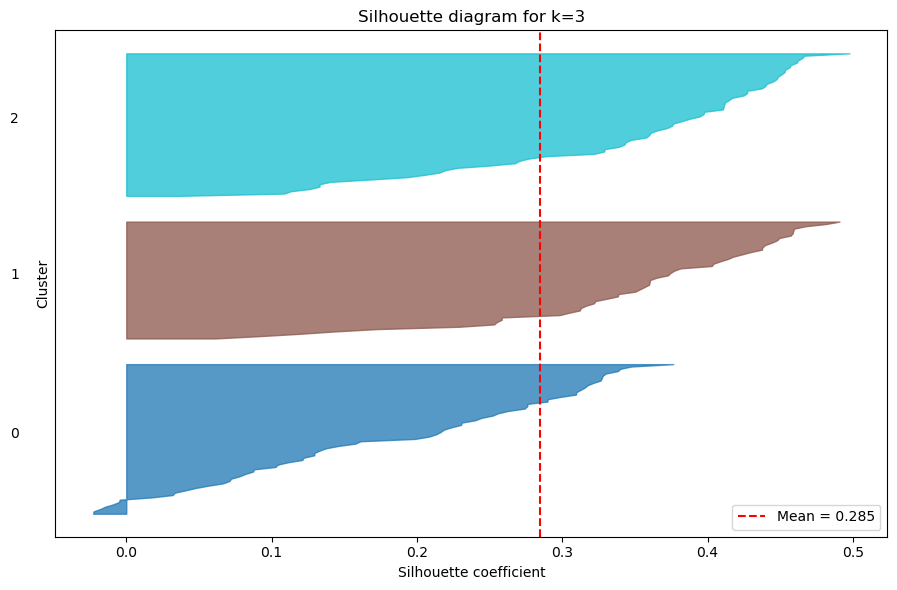

In [23]:
final_model = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
cluster_labels = final_model.fit_predict(X_scaled)
sample_silhouette_values = silhouette_samples(X_scaled, cluster_labels)
mean_silhouette = sample_silhouette_values.mean()

fig, ax = plt.subplots(figsize=(9, 6))
y_lower = 10
colors = plt.cm.tab10(np.linspace(0, 1, best_k))
for cluster_id, color in zip(range(best_k), colors):
    values = sample_silhouette_values[cluster_labels == cluster_id]
    values.sort()
    size = len(values)
    y_upper = y_lower + size
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, values, facecolor=color, edgecolor=color, alpha=0.75)
    ax.text(-0.08, y_lower + size / 2, str(cluster_id))
    y_lower = y_upper + 10

ax.axvline(mean_silhouette, color="red", linestyle="--", label=f"Mean = {mean_silhouette:.3f}")
ax.set(title=f"Silhouette diagram for k={best_k}", xlabel="Silhouette coefficient", ylabel="Cluster")
ax.set_yticks([])
ax.legend(loc="best")
plt.tight_layout()
plt.show()


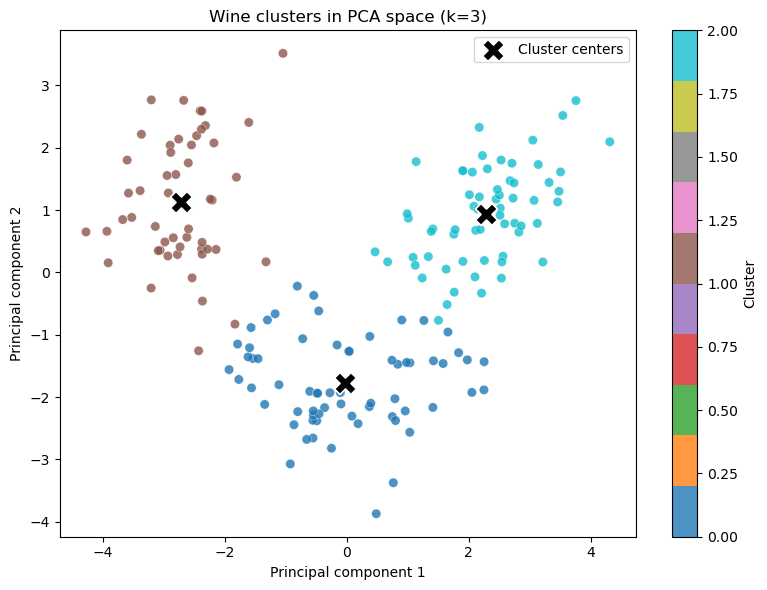

Variance explained by plotted components: 55.4%


In [24]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(final_model.cluster_centers_)

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap="tab10",
                     s=45, alpha=0.8, edgecolor="white", linewidth=0.3)
ax.scatter(centers_pca[:, 0], centers_pca[:, 1], marker="X", s=250,
           c="black", edgecolor="white", linewidth=1.2, label="Cluster centers")
ax.set(title=f"Wine clusters in PCA space (k={best_k})", xlabel="Principal component 1", ylabel="Principal component 2")
ax.legend()
plt.colorbar(scatter, ax=ax, label="Cluster")
plt.tight_layout()
plt.show()

print(f"Variance explained by plotted components: {pca.explained_variance_ratio_.sum():.1%}")


## Cluster profiles in original units

In [25]:
profile = X.assign(cluster=cluster_labels).groupby("cluster").mean().T
profile


cluster,0,1,2
alcohol,12.250923,13.134118,13.676774
malic_acid,1.897385,3.307255,1.997903
ash,2.231231,2.417647,2.466290
alcalinity_of_ash,20.063077,21.241176,17.462903
magnesium,92.738462,98.666667,107.967742
total_phenols,2.247692,1.683922,2.847581
flavanoids,2.050000,0.818824,3.003226
nonflavanoid_phenols,0.357692,0.451961,0.292097
proanthocyanins,1.624154,1.145882,1.922097
color_intensity,2.973077,7.234706,5.453548


In [ ]:
cluster_z_means = pd.DataFrame(X_scaled, columns=X.columns).assign(cluster=cluster_labels).groupby("cluster").mean()
overall_means = X.mean()

print("Business-readable summary")
print(f"The analysis tested k=2 through k=10 and selected k={best_k}, which had the highest mean silhouette score ({mean_silhouette:.3f}) among the candidates.")
print("Clusters describe similarity in standardized chemical measurements; they are not verified product or market segments.")
for cluster_id in range(best_k):
    size = int((cluster_labels == cluster_id).sum())
    top_features = cluster_z_means.loc[cluster_id].abs().sort_values(ascending=False).head(3).index
    descriptors = []
    for feature in top_features:
        direction = "above" if cluster_z_means.loc[cluster_id, feature] >= 0 else "below"
        descriptors.append(f"{feature} {direction} overall average (cluster mean {profile.loc[feature, cluster_id]:.2f}; overall {overall_means[feature]:.2f})")
    print(f"\nCluster {cluster_id}: {size} wines ({size / len(X):.1%} of the dataset).")
    print("  Most distinctive averages: " + "; ".join(descriptors) + ".")

comparison = pd.crosstab(pd.Series(cluster_labels, name="cluster"),
                         pd.Series([cultivar_names[i] for i in y_encoded], name="known cultivar"))
print("\nCluster vs. known cultivar counts (not used during model fitting):")
display(comparison)


Business-readable summary
The analysis tested k=2 through k=10 and selected k=3, which had the highest mean silhouette score (0.285) among the candidates.
Clusters describe similarity in standardized chemical measurements; they are not verified product or market segments.

Cluster 0: 65 wines (36.5% of the dataset).
  Most distinctive averages: alcohol below overall average (cluster mean 12.25; overall 13.00); color_intensity below overall average (cluster mean 2.97; overall 5.06); proline below overall average (cluster mean 510.17; overall 746.89).

Cluster 1: 51 wines (28.7% of the dataset).
  Most distinctive averages: od280/od315_of_diluted_wines below overall average (cluster mean 1.70; overall 2.61); flavanoids below overall average (cluster mean 0.82; overall 2.03); hue below overall average (cluster mean 0.69; overall 0.96).

Cluster 2: 62 wines (34.8% of the dataset).
  Most distinctive averages: proline above overall average (cluster mean 1100.23; overall 746.89); flavanoids 

known cultivar,class_0,class_1,class_2
cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0


# Method comparison: DBSCAN and hierarchical clustering

This section compares K-Means, DBSCAN, and agglomerative clustering using the same standardized features. DBSCAN noise points (label -1) are excluded from its Silhouette Score and reported separately. A silhouette score is calculated only when at least two clusters remain and the number of clusters is smaller than the number of scored observations.

In [27]:
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster


In [ ]:
dbscan_settings = [(eps, min_samples) for eps in [1.5, 2.0, 2.5, 3.0, 3.5]
                   for min_samples in [3, 5, 8]]
dbscan_rows = []
dbscan_models = {}

for eps, min_samples in dbscan_settings:
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)
    non_noise = labels != -1
    n_clusters = len(set(labels[non_noise]))
    n_noise = int((~non_noise).sum())
    score = np.nan
    if n_clusters >= 2 and non_noise.sum() > n_clusters:
        score = silhouette_score(X_scaled[non_noise], labels[non_noise])
    dbscan_rows.append({"eps": eps, "min_samples": min_samples,
                        "clusters (excluding noise)": n_clusters,
                        "noise points": n_noise,
                        "silhouette (excluding noise)": score})
    dbscan_models[(eps, min_samples)] = labels

dbscan_results = pd.DataFrame(dbscan_rows).sort_values(
    "silhouette (excluding noise)", ascending=False, na_position="last"
).reset_index(drop=True)
display(dbscan_results)


,eps,min_samples,clusters (excluding noise),noise points,silhouette (excluding noise)
0,2.0,8,3,117,0.435964
1,1.5,3,8,147,0.331067
2,2.5,8,2,30,0.318297
3,2.0,5,5,85,0.240461
4,3.0,3,2,7,0.239187
5,3.5,3,2,3,0.230781
6,2.0,3,5,64,0.211348
7,1.5,5,0,178,NaN
8,1.5,8,0,178,NaN
9,2.5,3,1,23,NaN


In [ ]:
valid_dbscan = dbscan_results.dropna(subset=["silhouette (excluding noise)"])
if len(valid_dbscan):
    best_dbscan_row = valid_dbscan.iloc[0]
    best_dbscan_params = (float(best_dbscan_row["eps"]), int(best_dbscan_row["min_samples"]))
    dbscan_labels = dbscan_models[best_dbscan_params]
    print(f"Selected DBSCAN eps={best_dbscan_params[0]}, min_samples={best_dbscan_params[1]} "
          f"(silhouette excluding noise={best_dbscan_row['silhouette (excluding noise)']:.3f}; "
          f"noise points={int(best_dbscan_row['noise points'])}).")
else:
    best_dbscan_params = None
    dbscan_labels = np.full(len(X), -1)
    print("DBSCAN did not produce at least two scoreable clusters on this parameter grid.")


Selected DBSCAN eps=2.0, min_samples=8 (silhouette excluding noise=0.436; noise points=117).


## Hierarchical clustering and dendrogram

The dendrogram uses Ward linkage on standardized features. We select the cluster count from the range 2-10 using the highest Silhouette Score. The horizontal cut marks the corresponding merge level.

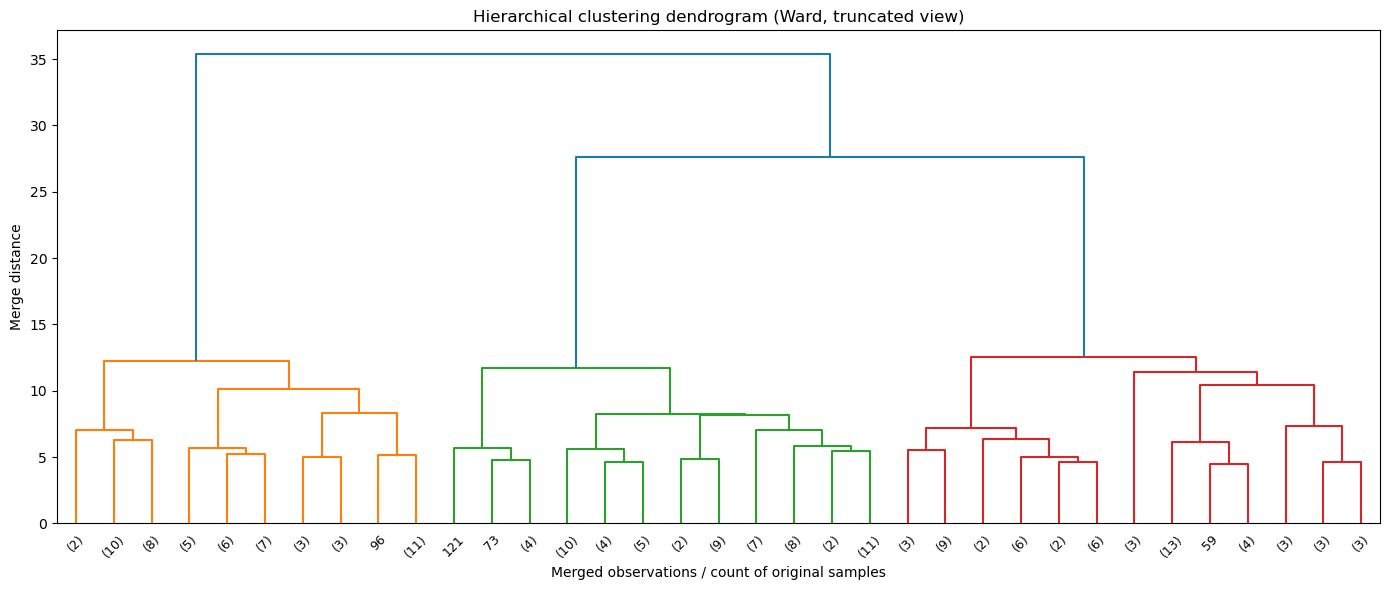

Selected 3 clusters by highest silhouette score: 0.277.


,k,silhouette
0,2,0.267013
1,3,0.277444
2,4,0.225837
3,5,0.186742
4,6,0.179666
5,7,0.186853
6,8,0.188347
7,9,0.191717
8,10,0.198568


In [30]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=35, show_leaf_counts=True,
           leaf_rotation=45, leaf_font_size=9)
plt.title("Hierarchical clustering dendrogram (Ward, truncated view)")
plt.xlabel("Merged observations / count of original samples")
plt.ylabel("Merge distance")
plt.tight_layout()
plt.show()

hierarchical_rows = []
hierarchical_labels = {}
for k in range(2, 11):
    labels = fcluster(Z, t=k, criterion="maxclust") - 1
    hierarchical_rows.append({"k": k, "silhouette": silhouette_score(X_scaled, labels)})
    hierarchical_labels[k] = labels
hierarchical_results = pd.DataFrame(hierarchical_rows)
best_hierarchical_k = int(hierarchical_results.loc[hierarchical_results["silhouette"].idxmax(), "k"])
hierarchical_cluster_labels = hierarchical_labels[best_hierarchical_k]
print(f"Selected {best_hierarchical_k} clusters by highest silhouette score: "
      f"{hierarchical_results['silhouette'].max():.3f}.")
display(hierarchical_results)


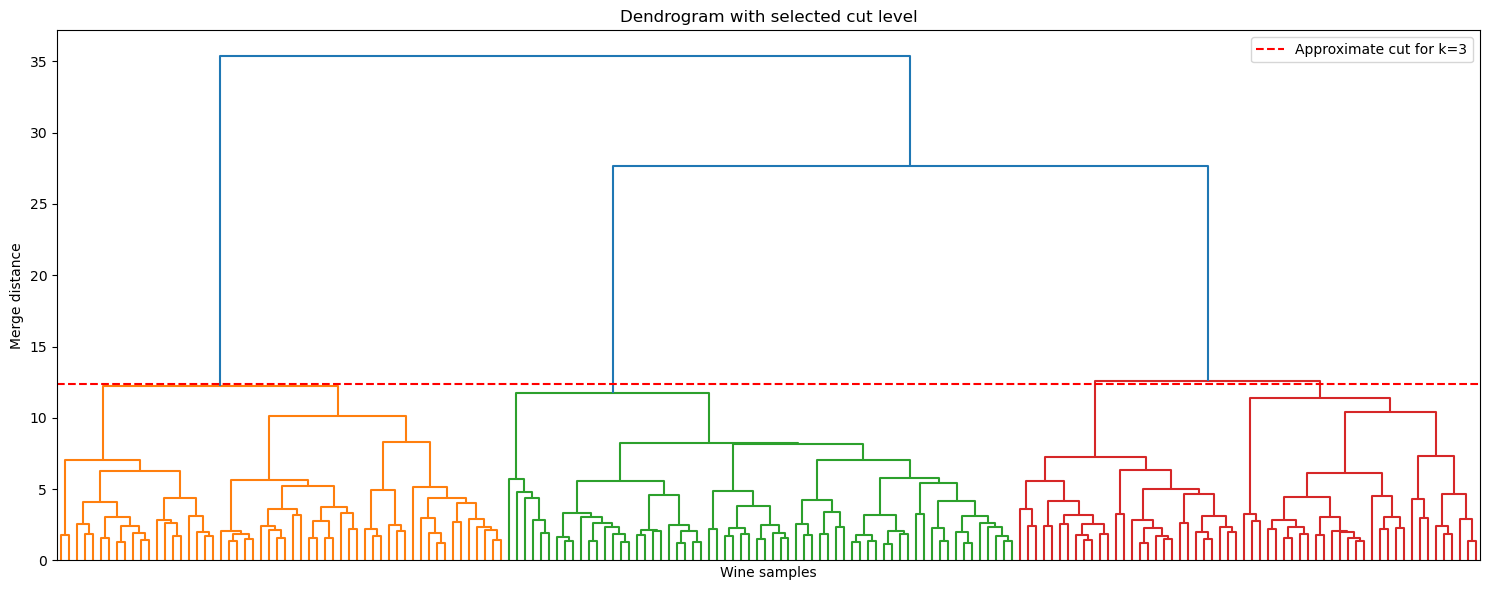

In [ ]:
plt.figure(figsize=(15, 6))
dendrogram(Z, no_labels=True, color_threshold=None)
cut_height = (Z[-(best_hierarchical_k + 1), 2] + Z[-best_hierarchical_k, 2]) / 2
plt.axhline(cut_height, color="red", linestyle="--",
            label=f"Approximate cut for k={best_hierarchical_k}")
plt.title("Dendrogram with selected cut level")
plt.xlabel("Wine samples")
plt.ylabel("Merge distance")
plt.legend()
plt.tight_layout()
plt.show()


## PCA and t-SNE visualizations

Compare the labels from all three methods in the same 2D projections. t-SNE is intended to visualize local structure; distances between groups in this plot should not be treated as exact distances in the full feature space.

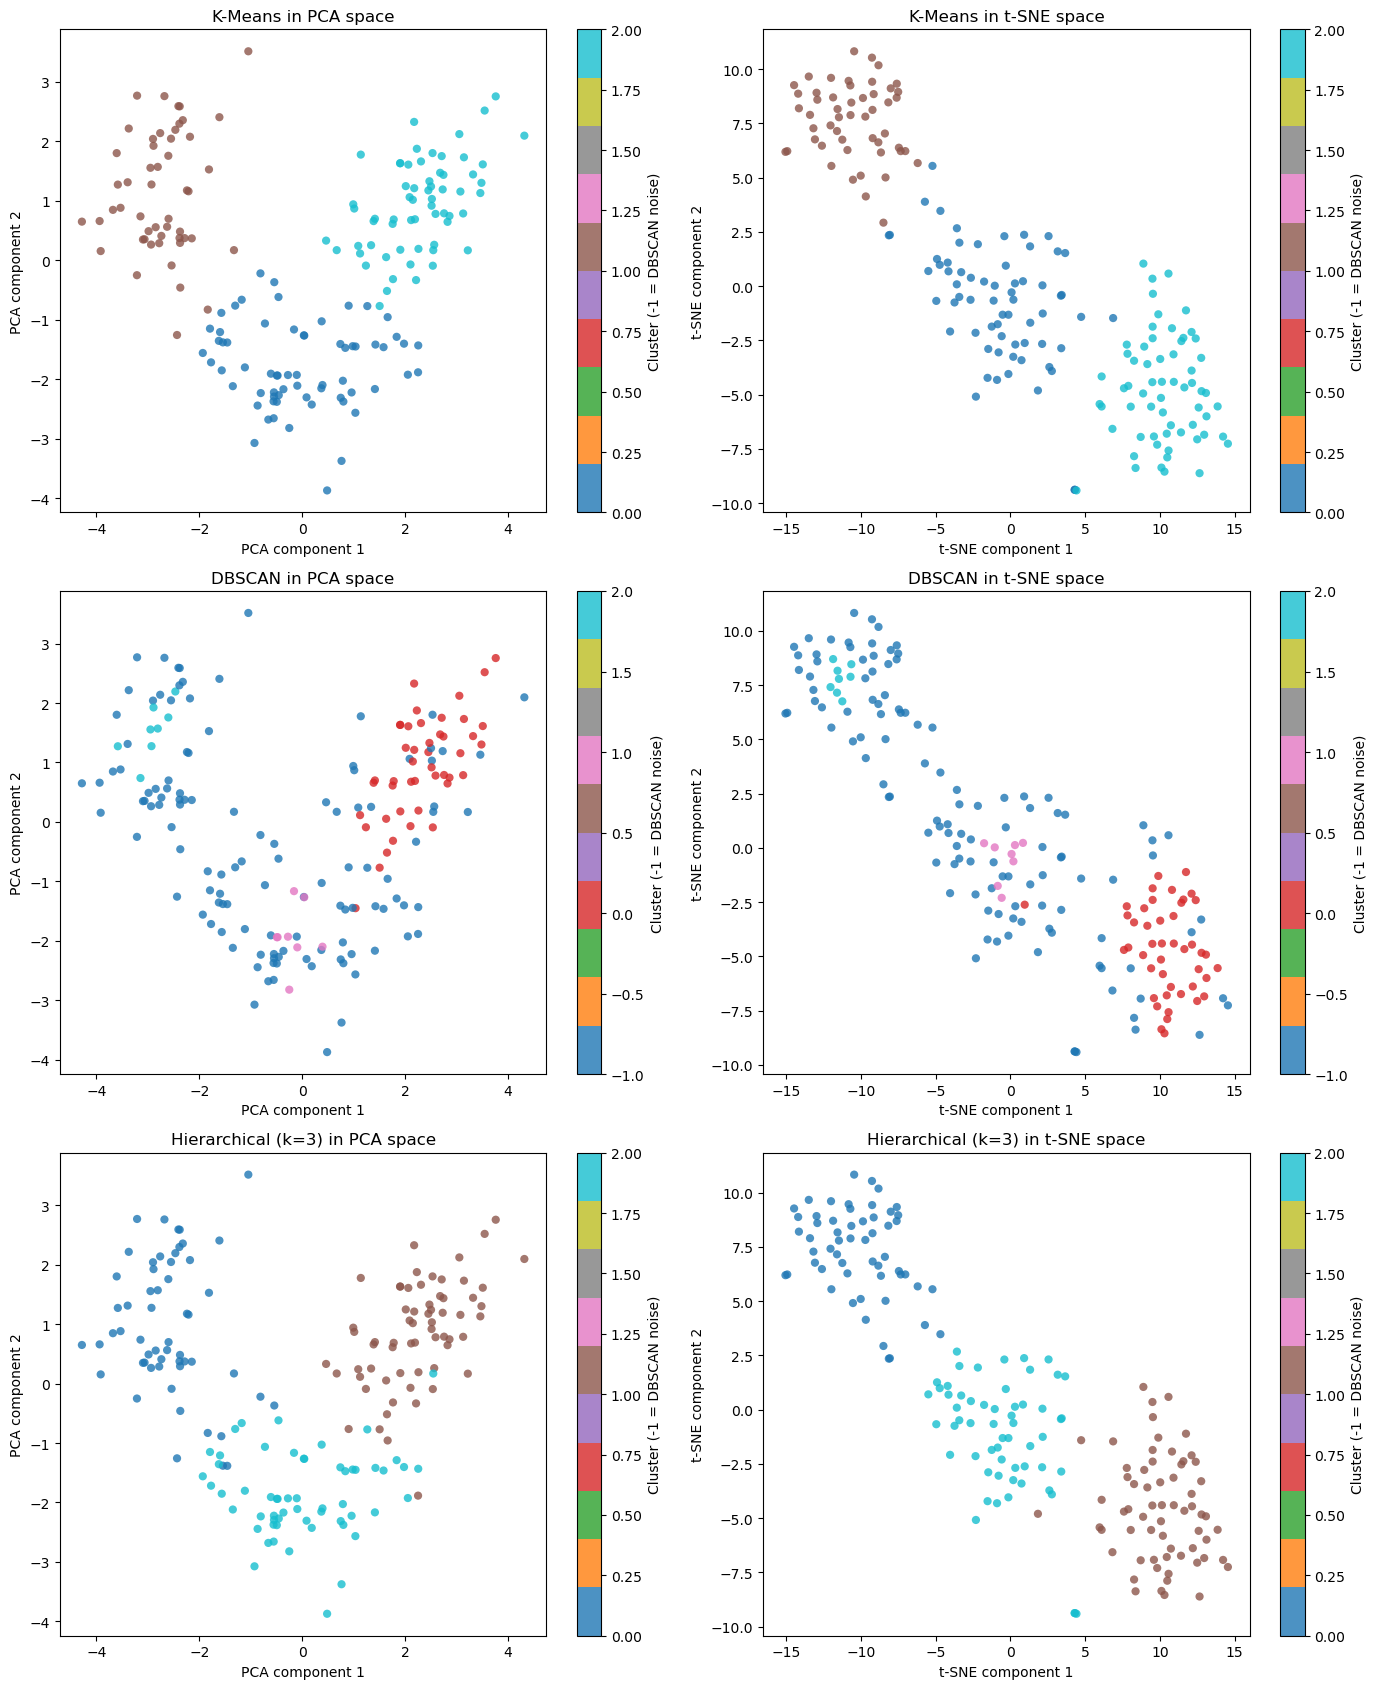

In [ ]:
tsne_perplexity = min(30, max(5, (len(X_scaled) - 1) // 3))
X_tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=tsne_perplexity,
              init="pca", learning_rate="auto").fit_transform(X_scaled)

label_sets = {
    "K-Means": cluster_labels,
    "DBSCAN": dbscan_labels,
    f"Hierarchical (k={best_hierarchical_k})": hierarchical_cluster_labels,
}
embeddings = {"PCA": X_pca, "t-SNE": X_tsne}
fig, axes = plt.subplots(3, 2, figsize=(14, 17))
for row, (method_name, labels) in enumerate(label_sets.items()):
    for col, (space_name, coordinates) in enumerate(embeddings.items()):
        ax = axes[row, col]
        points = ax.scatter(coordinates[:, 0], coordinates[:, 1], c=labels, cmap="tab10",
                            s=35, alpha=0.8, edgecolor="none")
        ax.set_title(f"{method_name} in {space_name} space")
        ax.set_xlabel(f"{space_name} component 1")
        ax.set_ylabel(f"{space_name} component 2")
        fig.colorbar(points, ax=ax, label="Cluster (-1 = DBSCAN noise)")
plt.tight_layout()
plt.show()


## Silhouette Score comparison

K-Means and Ward are scored on all observations. DBSCAN is scored on non-noise points, with its noise count reported separately. Its score therefore uses a subset of the data and should be compared with care.

In [33]:
comparison_rows = [{
    "method": f"K-Means (k={best_k})",
    "clusters": len(set(cluster_labels)), "noise points": 0,
    "silhouette": silhouette_score(X_scaled, cluster_labels),
    "scored observations": len(X_scaled),
}]

if best_dbscan_params is not None:
    valid = dbscan_labels != -1
    comparison_rows.append({
        "method": f"DBSCAN (eps={best_dbscan_params[0]}, min_samples={best_dbscan_params[1]})",
        "clusters": len(set(dbscan_labels[valid])), "noise points": int((~valid).sum()),
        "silhouette": silhouette_score(X_scaled[valid], dbscan_labels[valid]),
        "scored observations": int(valid.sum()),
    })
else:
    comparison_rows.append({"method": "DBSCAN (no valid partition)", "clusters": 0,
                            "noise points": len(X_scaled), "silhouette": np.nan,
                            "scored observations": 0})

comparison_rows.append({
    "method": f"Ward (k={best_hierarchical_k})",
    "clusters": len(set(hierarchical_cluster_labels)), "noise points": 0,
    "silhouette": silhouette_score(X_scaled, hierarchical_cluster_labels),
    "scored observations": len(X_scaled),
})
method_comparison = pd.DataFrame(comparison_rows).sort_values(
    "silhouette", ascending=False, na_position="last")
display(method_comparison)


,method,clusters,noise points,silhouette,scored observations
1,"DBSCAN (eps=2.0, min_samples=8)",3,117,0.435964,61
0,K-Means (k=3),3,0,0.284859,178
2,Ward (k=3),3,0,0.277444,178


## Segment interpretation

The profiles below show averages in the original measurement units and highlight chemical differences between groups. Cluster IDs are arbitrary; DBSCAN noise (-1) is shown separately. These are statistical groups based on chemical composition, not verified commercial categories.

In [34]:
def show_cluster_profiles(method_name, labels, include_noise=False):
    mask = np.ones(len(labels), dtype=bool) if include_noise else labels != -1
    observed_labels = sorted(np.unique(labels[mask]))
    if not len(observed_labels):
        print(f"{method_name}: no clusters available to profile.")
        return
    profiles = X.loc[mask].assign(cluster=labels[mask]).groupby("cluster").mean()
    scaled_profiles = pd.DataFrame(X_scaled, columns=X.columns).loc[mask].assign(
        cluster=labels[mask]).groupby("cluster").mean()
    print(f"\n{method_name}: group size and three most distinctive feature averages")
    for cluster_id in observed_labels:
        size = int((labels == cluster_id).sum())
        if cluster_id == -1:
            print(f"Noise: {size} wines were not assigned to a dense DBSCAN cluster.")
            continue
        top = scaled_profiles.loc[cluster_id].abs().sort_values(ascending=False).head(3).index
        descriptors = [
            f"{feature} {'above' if scaled_profiles.loc[cluster_id, feature] >= 0 else 'below'} "
            f"the overall average ({profiles.loc[cluster_id, feature]:.2f} vs. {X[feature].mean():.2f})"
            for feature in top
        ]
        print(f"Cluster {cluster_id}: {size} wines ({size / len(X):.1%}); " + "; ".join(descriptors) + ".")
    display(profiles)

show_cluster_profiles("K-Means", cluster_labels)
show_cluster_profiles("DBSCAN", dbscan_labels, include_noise=True)
show_cluster_profiles(f"Ward, k={best_hierarchical_k}", hierarchical_cluster_labels)



K-Means: group size and three most distinctive feature averages
Cluster 0: 65 wines (36.5%); alcohol below the overall average (12.25 vs. 13.00); color_intensity below the overall average (2.97 vs. 5.06); proline below the overall average (510.17 vs. 746.89).
Cluster 1: 51 wines (28.7%); od280/od315_of_diluted_wines below the overall average (1.70 vs. 2.61); flavanoids below the overall average (0.82 vs. 2.03); hue below the overall average (0.69 vs. 0.96).
Cluster 2: 62 wines (34.8%); proline above the overall average (1100.23 vs. 746.89); flavanoids above the overall average (3.00 vs. 2.03); total_phenols above the overall average (2.85 vs. 2.30).


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,
0,12.250923,1.897385,2.231231,20.063077,92.738462,2.247692,2.050000,0.357692,1.624154,2.973077,1.062708,2.803385,510.169231
1,13.134118,3.307255,2.417647,21.241176,98.666667,1.683922,0.818824,0.451961,1.145882,7.234706,0.691961,1.696667,619.058824
2,13.676774,1.997903,2.466290,17.462903,107.967742,2.847581,3.003226,0.292097,1.922097,5.453548,1.065484,3.163387,1100.225806



DBSCAN: group size and three most distinctive feature averages
Noise: 117 wines were not assigned to a dense DBSCAN cluster.
Cluster 0: 45 wines (25.3%); proline above the overall average (1141.64 vs. 746.89); flavanoids above the overall average (2.97 vs. 2.03); alcohol above the overall average (13.76 vs. 13.00).
Cluster 1: 8 wines (4.5%); color_intensity below the overall average (2.68 vs. 5.06); proline below the overall average (423.38 vs. 746.89); alcohol below the overall average (12.27 vs. 13.00).
Cluster 2: 8 wines (4.5%); color_intensity above the overall average (8.70 vs. 5.06); hue below the overall average (0.62 vs. 0.96); od280/od315_of_diluted_wines below the overall average (1.68 vs. 2.61).


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,
-1,12.738034,2.514872,2.345128,20.150427,98.709402,2.116325,1.736410,0.384872,1.534872,4.756667,0.941162,2.428291,625.649573
0,13.757111,1.744222,2.440444,17.148889,106.200000,2.832667,2.970222,0.288667,1.836444,5.618444,1.073111,3.160444,1141.644444
1,12.267500,1.848750,2.232500,21.600000,87.500000,2.426250,2.305000,0.351250,1.450000,2.676250,0.882500,3.143750,423.375000
2,13.318750,3.543750,2.397500,21.000000,90.750000,1.755000,0.743750,0.447500,1.170000,8.696250,0.620000,1.675000,623.125000



Ward, k=3: group size and three most distinctive feature averages
Cluster 0: 56 wines (31.5%); od280/od315_of_diluted_wines below the overall average (1.73 vs. 2.61); flavanoids below the overall average (0.85 vs. 2.03); hue below the overall average (0.72 vs. 0.96).
Cluster 1: 64 wines (36.0%); proline above the overall average (1076.05 vs. 746.89); flavanoids above the overall average (3.01 vs. 2.03); total_phenols above the overall average (2.85 vs. 2.30).
Cluster 2: 58 wines (32.6%); alcohol below the overall average (12.20 vs. 13.00); color_intensity below the overall average (2.90 vs. 5.06); proline below the overall average (501.43 vs. 746.89).


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,
0,13.061607,3.166607,2.412857,21.003571,99.857143,1.694286,0.847857,0.449464,1.129286,6.850179,0.721000,1.727321,624.946429
1,13.669219,1.970000,2.463125,17.528125,106.156250,2.850000,3.009688,0.291094,1.908125,5.450000,1.071406,3.158437,1076.046875
2,12.203966,1.938966,2.215172,20.208621,92.551724,2.262931,2.088103,0.355345,1.686552,2.895345,1.060000,2.862241,501.431034
